In [1]:

print("My first Machine Learning project!")


My first Machine Learning project!


In [3]:

from google.colab import files

uploaded = files.upload()


Saving train.csv to train.csv


In [4]:

import pandas as pd

df = pd.read_csv("train.csv")

print(df.shape)
print(df.head())


(1460, 81)
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  YrSold  SaleType  SaleCondition  SalePrice  
0   2008  

In [5]:

print(df.columns.tolist())
print(df[["GrLivArea", "BedroomAbvGr", "SalePrice"]].head())


['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'PoolQC'

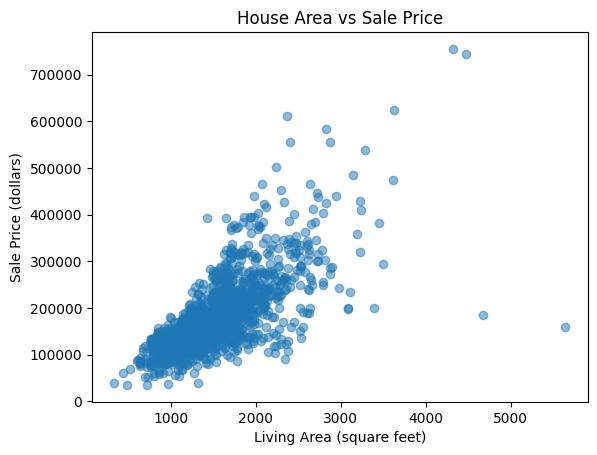

In [6]:

import matplotlib.pyplot as plt

plt.scatter(df["GrLivArea"], df["SalePrice"], alpha=0.5)
plt.xlabel("Living Area (square feet)")
plt.ylabel("Sale Price (dollars)")
plt.title("House Area vs Sale Price")
plt.show()


In [7]:

from sklearn.model_selection import train_test_split

X = df[["GrLivArea"]]
y = df["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training houses:", len(X_train))
print("Testing houses:", len(X_test))


Training houses: 1168
Testing houses: 292


In [8]:

from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print("Model trained successfully!")
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)


Model trained successfully!
Slope: 102.48895891672333
Intercept: 24899.74815733818


In [9]:

new_house = pd.DataFrame({
    "GrLivArea": [1500]
})

predicted_price = model.predict(new_house)

print("Predicted price: $", round(predicted_price[0], 2))


Predicted price: $ 178633.19


In [10]:

from sklearn.metrics import mean_absolute_error

predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)

print("Mean Absolute Error: $", round(mae, 2))


Mean Absolute Error: $ 38341.2
